# Segmentasi Pelanggan E-Commerce Berdasarkan Karakteristik Perilaku Belanja dan Aktivitas Digital Menggunakan Algoritma Clustering untuk Strategi Personalisasi Pemasaran

# Profile Kelompok

1. Putri Asmiranti Samiun		(123240033)
2. Briliant Priscilla	  		(123240068)
3. Andini Papa Sulima 		(123240118)
4. Nathania Keyne Rahmawati 	(123240201)


# Data Understanding
Fase ini bertujuan untuk memahami karakteristik awal dari dataset, mendeteksi potensi masalah kualitas data, dan menemukan wawasan awal (*insights*) terkait perilaku pelanggan E-Commerce sebelum masuk ke tahap prapemrosesan dan pemodelan *clustering*.

## Latar Belakang & Tujuan Analisis
Pemahaman terhadap profil pelanggan (*Customer Profiling*) sangat krusial bagi bisnis *e-commerce* untuk mengidentifikasi kelompok pelanggan dengan karakteristik serupa. Melalui pendekatan *unsupervised learning* (Clustering), analisis ini bertujuan untuk mengelompokkan pelanggan berdasarkan metrik keterlibatan aplikasi, riwayat pesanan, dan karakteristik demografis, yang nantinya dapat dimanfaatkan oleh tim bisnis untuk merumuskan strategi personalisasi pemasaran (*targeted marketing*) serta menekan angka *churn*.

## Data dictionary (variabel, tipe, unit)
Tabel kamus data di bawah ini mendefinisikan seluruh variabel yang terdapat di dalam dataset *E-Commerce* (`E Comm` sheet), lengkap dengan tipe data asli dari sistem dan unit ukurannya:

| Kolom | Tipe | Unit | Keterangan |
| :--- | :--- | :--- | :--- |
| `CustomerID` | int64 | ID | ID unik pelanggan |
| `Churn` | int64 | Flag (0/1) | Penanda *churn* atau indikator pelanggan berhenti |
| `Tenure` | float64 | Bulan | Masa berlangganan pelanggan di dalam organisasi/perusahaan |
| `PreferredLoginDevice` | object | Kategori | Perangkat *login* yang lebih disukai atau sering digunakan pelanggan |
| `CityTier` | int64 | Tingkatan | Tingkatan atau kategori kota tempat tinggal pelanggan |
| `WarehouseToHome` | float64 | Kilometer / Mil | Jarak antara gudang pengiriman dengan rumah pelanggan |
| `PreferredPaymentMode` | object | Kategori | Metode pembayaran pilihan yang sering digunakan pelanggan |
| `Gender` | object | Kategori | Jenis kelamin pelanggan |
| `HourSpendOnApp` | float64 | Jam | Jumlah jam yang dihabiskan pelanggan pada aplikasi seluler atau situs web |
| `NumberOfDeviceRegistered` | int64 | Unit | Total perangkat yang didaftarkan oleh pelanggan tertentu |
| `PreferedOrderCat` | object | Kategori | Kategori pesanan yang menjadi preferensi pelanggan pada bulan lalu |
| `SatisfactionScore` | int64 | Skor (1-5) | Skor kepuasan pelanggan terhadap layanan yang diberikan |
| `MaritalStatus` | object | Kategori | Status pernikahan dari pelanggan |
| `NumberOfAddress` | int64 | Unit | Total alamat pengiriman yang ditambahkan oleh pelanggan tertentu |
| `Complain` | int64 | Flag (0/1) | Indikator apakah pelanggan pernah mengajukan keluhan pada bulan lalu |
| `OrderAmountHikeFromlastYear` | float64 | Persen (%) | Persentase peningkatan jumlah pesanan dibandingkan dengan tahun lalu |
| `CouponUsed` | float64 | Unit | Total kupon diskon yang telah digunakan pelanggan pada bulan lalu |
| `OrderCount` | float64 | Unit | Total pesanan yang telah berhasil dibuat pada bulan lalu |
| `DaySinceLastOrder` | float64 | Hari | Jumlah hari yang berlalu sejak pesanan terakhir pelanggan |
| `CashbackAmount` | float64 | Mata Uang | Rata-rata nominal *cashback* yang diterima pelanggan pada bulan lalu |

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

---
## Bagian 1: Data Ingestion 

Baca file `E_Commerce_Dataset.csv` ke dalam DataFrame `df`. Tampilkan 5 baris teratas dan ukuran data (jumlah baris dan kolom).

In [ ]:
# Membaca file CSV ke dalam DataFrame df menggunakan pandas
df = pd.read_csv('E_Commerce_Dataset.csv')

# Menampilkan 5 baris teratas untuk inspeksi struktur data awal
display(df.head())

# Menampilkan ukuran data (jumlah baris dan kolom)
print("Ukuran data (baris, kolom):", df.shape)

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,160
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,121
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,130


Ukuran data (baris, kolom): (5630, 20)


Tampilkan informasi ringkas dataset. Sebutkan kolom yang tipe datanya kurang sesuai dan tipe yang seharusnya.

In [ ]:
# Menampilkan informasi ringkas dataset (tipe data, non-null count)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

Statistika Deskriptif


In [ ]:
describe = df.describe()
print(describe)

         CustomerID        Churn       Tenure     CityTier  WarehouseToHome  \
count   5630.000000  5630.000000  5366.000000  5630.000000      5379.000000   
mean   52815.500000     0.168384    10.189899     1.654707        15.639896   
std     1625.385339     0.374240     8.557241     0.915389         8.531475   
min    50001.000000     0.000000     0.000000     1.000000         5.000000   
25%    51408.250000     0.000000     2.000000     1.000000         9.000000   
50%    52815.500000     0.000000     9.000000     1.000000        14.000000   
75%    54222.750000     0.000000    16.000000     3.000000        20.000000   
max    55630.000000     1.000000    61.000000     3.000000       127.000000   

       HourSpendOnApp  NumberOfDeviceRegistered  SatisfactionScore  \
count     5375.000000               5630.000000        5630.000000   
mean         2.931535                  3.688988           3.066785   
std          0.721926                  1.023999           1.380194   
min     

---
## Bagian 2: Audit Kualitas Data dan Cleaning (Poin 9–11)

Audit menggunakan df dari CSV mentah. Data awal dipertahankan, sedangkan cleaning dilakukan pada salinan df_clean. Jumlah nilai kosong menunjukkan jumlah sel, bukan jumlah pelanggan.

### 2.1 Missing value dan duplikasi
Periksa jumlah dan persentase nilai kosong setiap kolom, baris terdampak, duplikat seluruh baris, dan pengulangan ID pelanggan. Nilai sama dalam satu kolom tidak otomatis merupakan duplikat pelanggan.

In [ ]:
n_awal = len(df)
missing_awal = pd.DataFrame({'Jumlah kosong': df.isna().sum(),
    'Persen kosong': (df.isna().mean() * 100).round(2)})
display(missing_awal)
print(f'Jumlah sel kosong: {df.isna().sum().sum():,}')
print(f'Pelanggan dengan nilai kosong: {df.isna().any(axis=1).sum():,} ({df.isna().any(axis=1).mean()*100:.2f}%)')
print(f'Duplikat baris lengkap: {df.duplicated().sum()}')
print(f'CustomerID kosong: {df.CustomerID.isna().sum()} | CustomerID berulang: {df.CustomerID.duplicated().sum()}')

,Jumlah kosong,Persen kosong
CustomerID,0,0.00
Churn,0,0.00
Tenure,264,4.69
PreferredLoginDevice,0,0.00
CityTier,0,0.00
WarehouseToHome,251,4.46
PreferredPaymentMode,0,0.00
Gender,0,0.00
HourSpendOnApp,255,4.53
NumberOfDeviceRegistered,0,0.00


Jumlah sel kosong: 1,856
Pelanggan dengan nilai kosong: 1,856 (32.97%)
Duplikat baris lengkap: 0
CustomerID kosong: 0 | CustomerID berulang: 0


### 2.2 Audit outlier pada data mentah
Metode IQR menandai nilai di bawah Q1 − 1,5 × IQR atau di atas Q3 + 1,5 × IQR. Persentase dihitung terhadap nilai yang tersedia di kolom tersebut. Penanda ini bukan bukti kesalahan. Jumlah antar kolom tidak dapat dijumlahkan sebagai jumlah pelanggan unik.

CustomerID adalah identitas; Churn dan Complain adalah biner; CityTier dan SatisfactionScore adalah ordinal. Variabel tersebut tidak diuji sebagai kontinu. Variabel hitungan tetap ditampilkan secara eksploratif dan ditafsirkan hati-hati, terutama saat IQR kecil.

In [ ]:
fitur_iqr = ['Tenure', 'WarehouseToHome', 'HourSpendOnApp',
    'NumberOfDeviceRegistered', 'NumberOfAddress', 'OrderAmountHikeFromlastYear',
    'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
def tabel_iqr(data):
    records = []
    for col in fitur_iqr:
        s = data[col].dropna()
        q1, q3 = s.quantile([.25, .75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        flagged = (s < lower) | (s > upper)
        records.append({'Kolom': col, 'N tersedia': len(s), 'Q1': q1, 'Q3': q3,
            'Batas bawah': lower, 'Batas atas': upper, 'Minimum': s.min(),
            'Maksimum': s.max(), 'Jumlah outlier': int(flagged.sum()),
            'Persen outlier': round(flagged.mean() * 100, 2)})
    return pd.DataFrame(records).set_index('Kolom')
outlier_awal = tabel_iqr(df)
display(outlier_awal.round(2))

,N tersedia,Q1,Q3,Batas bawah,Batas atas,Minimum,Maksimum,Jumlah outlier,Persen outlier
Kolom,,,,,,,,,
Tenure,5366,2.0,16.0,-19.0,37.0,0.0,61.0,4,0.07
WarehouseToHome,5379,9.0,20.0,-7.5,36.5,5.0,127.0,2,0.04
HourSpendOnApp,5375,2.0,3.0,0.5,4.5,0.0,5.0,6,0.11
NumberOfDeviceRegistered,5630,3.0,4.0,1.5,5.5,1.0,6.0,397,7.05
NumberOfAddress,5630,2.0,6.0,-4.0,12.0,1.0,22.0,4,0.07
OrderAmountHikeFromlastYear,5365,13.0,18.0,5.5,25.5,11.0,26.0,33,0.62
CouponUsed,5374,1.0,2.0,-0.5,3.5,0.0,16.0,629,11.70
OrderCount,5372,1.0,3.0,-2.0,6.0,1.0,16.0,703,13.09
DaySinceLastOrder,5323,2.0,7.0,-5.5,14.5,0.0,46.0,62,1.16


### 2.3 Konsistensi kategori dan rentang nilai
Variasi CC/Credit Card dan COD/Cash on Delivery diperiksa untuk penyeragaman. Phone dan Mobile Phone tampak serupa, tetapi tidak disatukan tanpa dokumentasi sumber yang memastikan maknanya sama. Pemeriksaan rentang berikut menguji aturan yang tercantum, bukan membuktikan seluruh nilai benar.

In [ ]:
kategori = ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']
for col in kategori:
    print()
    print(col + ':')
    print(df[col].value_counts(dropna=False).to_string())
aturan = {'Churn': [0, 1], 'Complain': [0, 1], 'CityTier': [1, 2, 3],
          'SatisfactionScore': [1, 2, 3, 4, 5]}
cek_kategori = pd.Series({col: (~df[col].isin(valid) & df[col].notna()).sum()
    for col, valid in aturan.items()}, name='Di luar kategori yang diharapkan')
display(cek_kategori.to_frame())
display(pd.DataFrame({'Nilai negatif': (df[fitur_iqr] < 0).sum()}))


PreferredLoginDevice:
PreferredLoginDevice
Mobile Phone    2765
Computer        1634
Phone           1231

PreferredPaymentMode:
PreferredPaymentMode
Debit Card          2314
Credit Card         1501
E wallet             614
UPI                  414
COD                  365
CC                   273
Cash on Delivery     149

Gender:
Gender
Male      3384
Female    2246

PreferedOrderCat:
PreferedOrderCat
Laptop & Accessory    2050
Mobile Phone          1271
Fashion                826
Mobile                 809
Grocery                410
Others                 264

MaritalStatus:
MaritalStatus
Married     2986
Single      1796
Divorced     848


,Di luar kategori yang diharapkan
Churn,0
Complain,0
CityTier,0
SatisfactionScore,0


,Nilai negatif
Tenure,0
WarehouseToHome,0
HourSpendOnApp,0
NumberOfDeviceRegistered,0
NumberOfAddress,0
OrderAmountHikeFromlastYear,0
CouponUsed,0
OrderCount,0
DaySinceLastOrder,0
CashbackAmount,0


### 2.4 Keputusan dan penerapan cleaning

| Masalah | Keputusan | Alasan dan batasan |
|---|---|---|
| Nilai kosong pada tujuh kolom numerik | Isi dengan median setiap kolom dari data mentah | Melanjutkan pendekatan Biyan, mempertahankan pelanggan, dan median lebih tahan terhadap nilai ekstrem. Imputasi dapat mengurangi variasi data. |
| Duplikat baris dan ID | Selidiki jika ditemukan; data saat ini tidak memiliki keduanya | Nilai sama pada satu kolom bukan bukti duplikasi. ID berulang tidak otomatis dihapus tanpa konteks. |
| Kategori pembayaran | CC menjadi Credit Card; COD menjadi Cash on Delivery | Singkatan dan bentuk panjang merujuk metode yang sama. Label telepon dipertahankan hingga definisinya dikonfirmasi. |
| Nilai ekstrem menurut IQR | Dipertahankan | IQR hanya penanda statistik; belum ada bukti kesalahan input. Nilai ekstrem bisa penting untuk segmentasi. K-Means dan StandardScaler sensitif terhadap nilai ekstrem, sehingga pengaruhnya perlu dievaluasi. |

Median dihitung dari data awal yang tersedia. Jika kelak dibuat pemisahan train/test, hitung median dari data latih saja untuk mencegah kebocoran data.

In [ ]:
df_clean = df.copy(deep=True)
cols_to_fill = ['Tenure', 'WarehouseToHome', 'HourSpendOnApp',
    'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder']
median_imputasi = df[cols_to_fill].median()
df_clean[cols_to_fill] = df_clean[cols_to_fill].fillna(median_imputasi)
df_clean['PreferredPaymentMode'] = df_clean['PreferredPaymentMode'].replace({
    'CC': 'Credit Card', 'COD': 'Cash on Delivery'})
display(pd.DataFrame({'Jumlah diisi': df[cols_to_fill].isna().sum(), 'Median pengisi': median_imputasi}))
assert len(df_clean) == len(df)
assert df_clean[cols_to_fill].isna().sum().sum() == 0
assert df_clean['CustomerID'].equals(df['CustomerID'])

,Jumlah diisi,Median pengisi
Tenure,264,9.0
WarehouseToHome,251,14.0
HourSpendOnApp,255,3.0
OrderAmountHikeFromlastYear,265,15.0
CouponUsed,256,1.0
OrderCount,258,2.0
DaySinceLastOrder,307,3.0


### 2.5 Perbandingan sebelum dan sesudah cleaning
Perbandingan mencakup nilai kosong semua kolom, jumlah baris, ID dan duplikasi. Statistik dan distribusi menunjukkan dampak imputasi. Perbandingan kategori pembayaran membuktikan penggabungan label.

In [ ]:
perbandingan_missing = pd.DataFrame({
    'Kosong sebelum': df.isna().sum(), 'Kosong sesudah': df_clean.isna().sum(),
    '% sebelum': (df.isna().mean() * 100).round(2),
    '% sesudah': (df_clean.isna().mean() * 100).round(2)})
display(perbandingan_missing)
ringkasan = pd.DataFrame({
    'Sebelum': [len(df), len(df.columns), int(df.isna().sum().sum()), int(df.isna().any(axis=1).sum()), int(df.duplicated().sum()), int(df.CustomerID.duplicated().sum())],
    'Sesudah': [len(df_clean), len(df_clean.columns), int(df_clean.isna().sum().sum()), int(df_clean.isna().any(axis=1).sum()), int(df_clean.duplicated().sum()), int(df_clean.CustomerID.duplicated().sum())]
}, index=['Jumlah baris', 'Jumlah kolom', 'Jumlah sel kosong', 'Baris dengan nilai kosong', 'Duplikat baris lengkap', 'CustomerID berulang'])
display(ringkasan)
payment_compare = pd.concat([df.PreferredPaymentMode.value_counts().rename('Sebelum'),
    df_clean.PreferredPaymentMode.value_counts().rename('Sesudah')], axis=1).fillna(0).astype(int)
display(payment_compare)
assert payment_compare['Sebelum'].sum() == payment_compare['Sesudah'].sum() == len(df)
stat_before = df[cols_to_fill].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T
stat_after = df_clean[cols_to_fill].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T
display(pd.concat({'Sebelum': stat_before, 'Sesudah': stat_after}, axis=1).round(2))
outlier_sesudah = tabel_iqr(df_clean)
display(pd.DataFrame({'IQR sebelum': outlier_awal['Jumlah outlier'], 'IQR sesudah': outlier_sesudah['Jumlah outlier']}))
print('Batas IQR dihitung ulang pada masing-masing kondisi; jumlah yang berubah tidak berarti outlier dihapus.')

,Kosong sebelum,Kosong sesudah,% sebelum,% sesudah
CustomerID,0,0,0.00,0.0
Churn,0,0,0.00,0.0
Tenure,264,0,4.69,0.0
PreferredLoginDevice,0,0,0.00,0.0
CityTier,0,0,0.00,0.0
WarehouseToHome,251,0,4.46,0.0
PreferredPaymentMode,0,0,0.00,0.0
Gender,0,0,0.00,0.0
HourSpendOnApp,255,0,4.53,0.0
NumberOfDeviceRegistered,0,0,0.00,0.0


,Sebelum,Sesudah
Jumlah baris,5630,5630
Jumlah kolom,20,20
Jumlah sel kosong,1856,0
Baris dengan nilai kosong,1856,0
Duplikat baris lengkap,0,0
CustomerID berulang,0,0


,Sebelum,Sesudah
PreferredPaymentMode,,
Debit Card,2314,2314
Credit Card,1501,1774
E wallet,614,614
UPI,414,414
COD,365,0
CC,273,0
Cash on Delivery,149,514


Sebelum                                  Sesudah  \
                              count   mean median   std   min    max   count   
Tenure                       5366.0  10.19    9.0  8.56   0.0   61.0  5630.0   
WarehouseToHome              5379.0  15.64   14.0  8.53   5.0  127.0  5630.0   
HourSpendOnApp               5375.0   2.93    3.0  0.72   0.0    5.0  5630.0   
OrderAmountHikeFromlastYear  5365.0  15.71   15.0  3.68  11.0   26.0  5630.0   
CouponUsed                   5374.0   1.75    1.0  1.89   0.0   16.0  5630.0   
OrderCount                   5372.0   3.01    2.0  2.94   1.0   16.0  5630.0   
DaySinceLastOrder            5323.0   4.54    3.0  3.65   0.0   46.0  5630.0   

                                                              
                              mean median   std   min    max  
Tenure                       10.13    9.0  8.36   0.0   61.0  
WarehouseToHome              15.57   14.0  8.35   5.0  127.0  
HourSpendOnApp                2.93    3.0  0.71   0.0    5.0  
OrderAmountHikeFromlastYear  15.67   15.0  3.59  11.0   26.0  
CouponUsed                    1.72    1.0  1.86   0.0   16.0  
OrderCount                    2.96    2.0  2.88   1.0   16.0  
DaySinceLastOrder             4.46    3.0  3.57   0.0   46.0

,IQR sebelum,IQR sesudah
Kolom,,
Tenure,4,4
WarehouseToHome,2,2
HourSpendOnApp,6,6
NumberOfDeviceRegistered,397,397
NumberOfAddress,4,4
OrderAmountHikeFromlastYear,33,33
CouponUsed,629,629
OrderCount,703,703
DaySinceLastOrder,62,62


Batas IQR dihitung ulang pada masing-masing kondisi; jumlah yang berubah tidak berarti outlier dihapus.


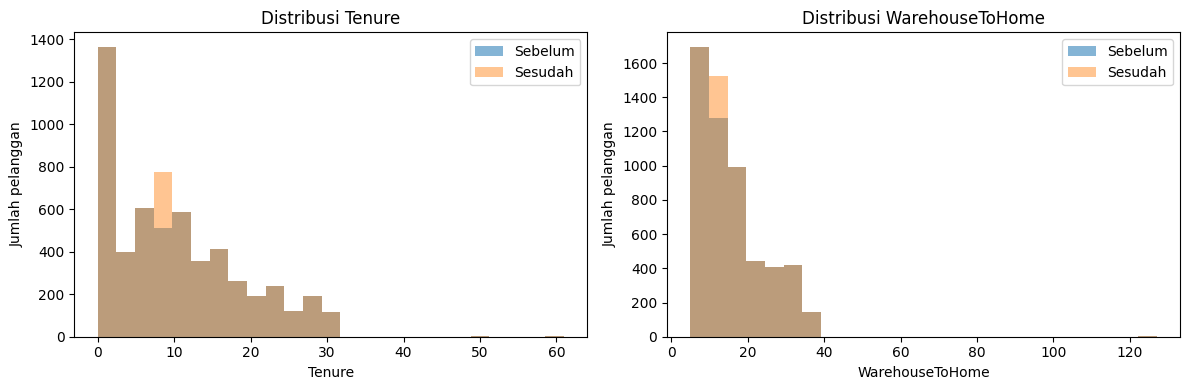

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['Tenure', 'WarehouseToHome']):
    ax.hist(df[col].dropna(), bins=25, alpha=.55, label='Sebelum')
    ax.hist(df_clean[col], bins=25, alpha=.45, label='Sesudah')
    ax.set_title(f'Distribusi {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Jumlah pelanggan')
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretasi:** penambahan frekuensi di sekitar median merupakan konsekuensi imputasi, bukan observasi baru. Tidak adanya nilai kosong setelah cleaning tidak berarti semua nilai imputasi diketahui benar. Dataset bersih diteruskan sebagai df_clean ke analisis dan pemodelan berikutnya.

---
Buat **boxplot** untuk kolom `CashbackAmount` dan `Tenure` (dua panel berdampingan, lengkap dengan judul). Lalu jawab:

(a) Apa yang bisa kamu simpulkan dari boxplot tersebut?

(b) Apakah ada outlier? Jika ada, di kolom mana dan kira-kira bernilai berapa?


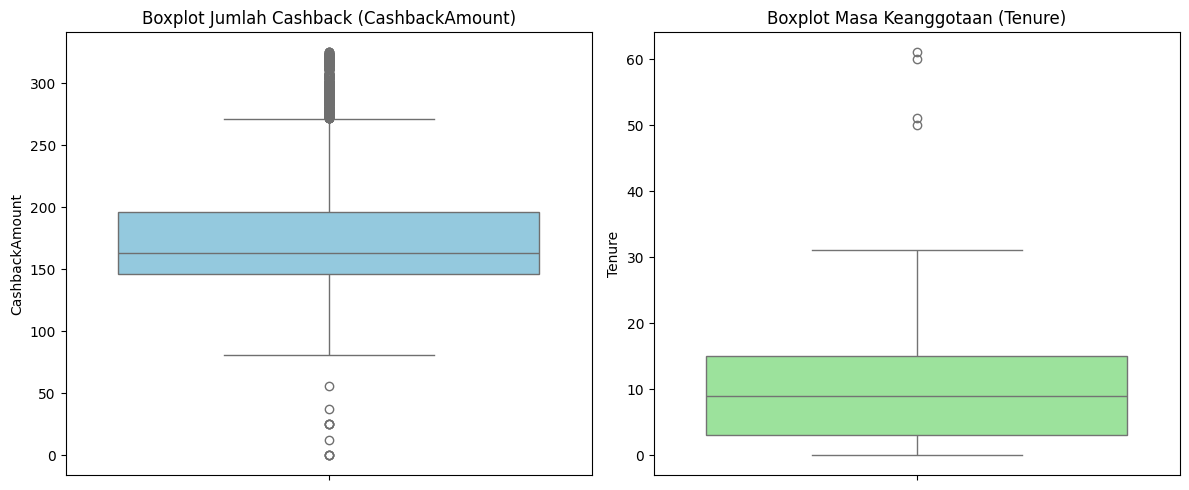

In [ ]:
# Boxplot CashbackAmount dan Tenure (dua panel)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df_clean['CashbackAmount'], ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot Jumlah Cashback (CashbackAmount)')

sns.boxplot(y=df_clean['Tenure'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot Masa Keanggotaan (Tenure)')

plt.tight_layout()
plt.show()

(a) Kesimpulan dari boxplot: Sebagian besar pelanggan memiliki jumlah cashback yang terkonsentrasi di rentang nilai menengah ke bawah, sementara dari sisi masa keanggotaan (Tenure), mayoritas pelanggan aktif dalam rentang waktu awal hingga menengah (sebagian besar di bawah kuartil atas).

(b) Adanya Outlier: Ya, terdapat outlier pada kedua kolom tersebut. Pada kolom CashbackAmount, terdapat titik-titik di atas batas atas (upper whisker) yang menunjukkan pelanggan yang menerima nilai cashback sangat tinggi (di atas 300). Pada kolom Tenure, terdapat juga titik-titik di bagian atas yang merepresentasikan pelanggan setia dengan masa keanggotaan yang jauh lebih lama dibandingkan rata-rata (mencapai lebih dari 50-60).

---
## Bagian 3: Exploratory Data Analysis

Tampilkan statistik deskriptif untuk kolom `Tenure`, `WarehouseToHome`, `HourSpendOnApp`, `OrderAmountHikeFromlastYear`, dan `CashbackAmount`.

In [ ]:
# Tampilkan statistik deskriptif untuk kolom Tenure, WarehouseToHome, HourSpendOnApp, OrderAmountHikeFromlastYear, dan CashbackAmount
df_clean[['Tenure', 'WarehouseToHome', 'HourSpendOnApp', 'OrderAmountHikeFromlastYear', 'CashbackAmount']].describe()

,Tenure,WarehouseToHome,HourSpendOnApp,OrderAmountHikeFromlastYear,CashbackAmount
count,5630.000000,5630.000000,5630.000000,5630.000000,5630.000000
mean,10.134103,15.566785,2.934636,15.674600,177.221492
std,8.357951,8.345961,0.705528,3.591058,49.193869
min,0.000000,5.000000,0.000000,11.000000,0.000000
25%,3.000000,9.000000,2.000000,13.000000,146.000000
50%,9.000000,14.000000,3.000000,15.000000,163.000000
75%,15.000000,20.000000,3.000000,18.000000,196.000000
max,61.000000,127.000000,5.000000,26.000000,325.000000


1. Variasi Jarak Pengiriman (WarehouseToHome): Nilai maksimum jarak dari gudang ke rumah pelanggan mencapai angka yang sangat tinggi (hingga 127) jika dibandingkan dengan nilai rata-rata dan kuartil ketiganya, yang mengindikasikan adanya kelompok pelanggan yang berlokasi sangat jauh dari gudang utama.

2. Sebaran Nilai Cashback (CashbackAmount): Standar deviasi pada jumlah cashback bernilai cukup besar dengan rentang dari 0 hingga lebih dari 300, menunjukkan bahwa variasi besaran reward cashback yang diterima oleh masing-masing pelanggan sangat beragam.

----
Buat histogram distribusi `CashbackAmount` dan `Tenure` dalam dua grafik berdampingan (lengkap dengan judul). Jelaskan bentuk distribusi masing-masing.

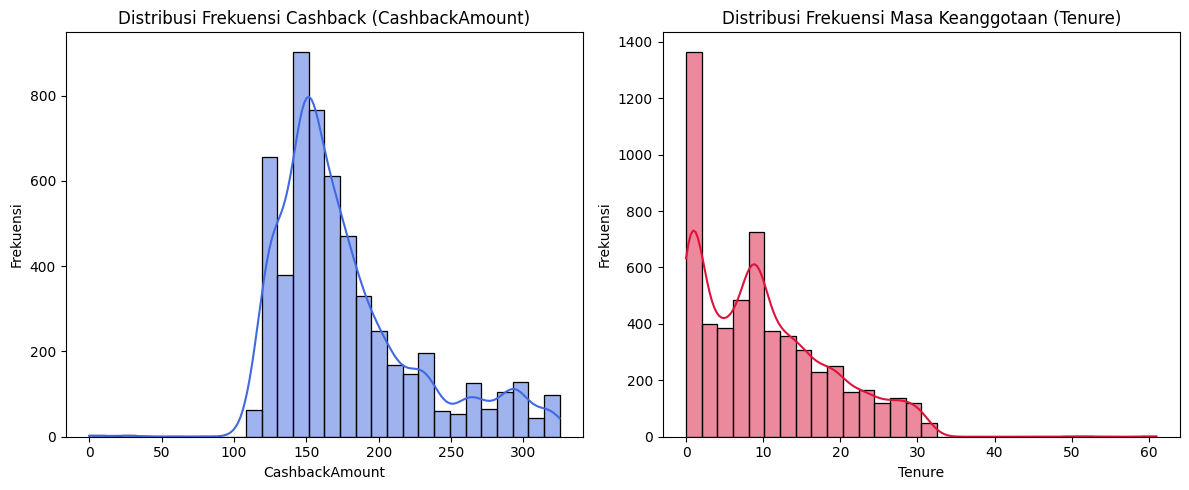

In [ ]:
# Histogram CashbackAmount dan Tenure (dua panel)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df_clean['CashbackAmount'], bins=30, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Distribusi Frekuensi Cashback (CashbackAmount)')
axes[0].set_xlabel('CashbackAmount')
axes[0].set_ylabel('Frekuensi')

sns.histplot(df_clean['Tenure'], bins=30, kde=True, ax=axes[1], color='crimson')
axes[1].set_title('Distribusi Frekuensi Masa Keanggotaan (Tenure)')
axes[1].set_xlabel('Tenure')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

`CashbackAmount` : Menunjukkan bentuk distribusi yang menceng ke kanan (right-skewed). Sebagian besar pelanggan terkonsentrasi pada kisaran nilai cashback rendah hingga menengah, sementara hanya sebagian kecil pelanggan yang mendapatkan nominal cashback dalam jumlah tinggi.

`Tenure` : Memiliki distribusi yang juga menceng ke kanan (right-skewed) dengan frekuensi tertinggi berada di masa keanggotaan awal (nilai tenure kecil). Hal ini mengindikasikan bahwa sebagian besar pelanggan baru bergabung dalam rentang waktu yang relatif singkat, sementara pelanggan dengan masa keanggotaan yang lama jumlahnya semakin sedikit.

-----
Buat boxplot `CashbackAmount` untuk setiap jenjang `SatisfactionScore` 

C:\Users\L O Q\AppData\Local\Temp\ipykernel_3564\383853759.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='SatisfactionScore', y='CashbackAmount', data=df_clean, palette='Set2', legend=False)


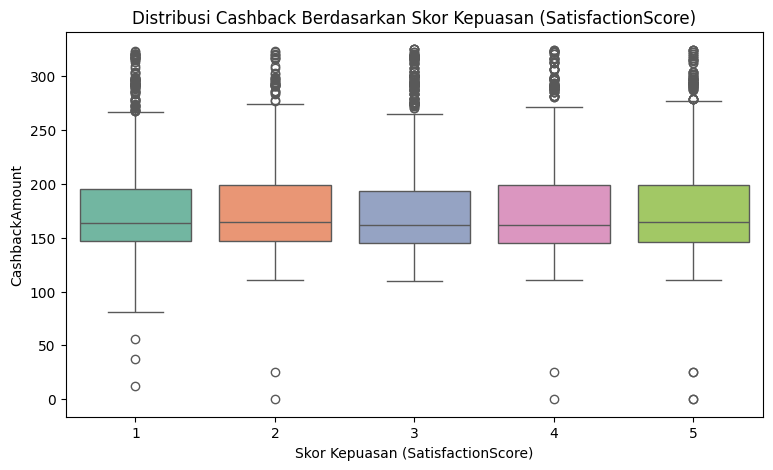

In [ ]:
# boxplot CashbackAmount per SatisfactionScore
plt.figure(figsize=(9, 5))
sns.boxplot(x='SatisfactionScore', y='CashbackAmount', data=df_clean, palette='Set2', legend=False)
plt.title('Distribusi Cashback Berdasarkan Skor Kepuasan (SatisfactionScore)')
plt.xlabel('Skor Kepuasan (SatisfactionScore)')
plt.ylabel('CashbackAmount')
plt.show()

Pola yang terlihat adalah tingkat kepuasan pelanggan (SatisfactionScore) tidak menunjukkan perbedaan yang drastis terhadap perolehan jumlah cashback (CashbackAmount). Rata-rata besaran cashback di setiap level skor kepuasan cenderung berada pada kisaran nilai yang hampir serupa. Namun, jika dihubungkan dengan variabel seperti Churn, pelanggan dengan skor kepuasan yang lebih rendah (SatisfactionScore 1 atau 2) umumnya memiliki tingkat komplain yang lebih tinggi dan probabilitas churn yang lebih besar dibandingkan pelanggan dengan skor kepuasan tinggi.

---
Buat heatmap korelasi (dengan angka). Jelaskan 2 temuan menarik.

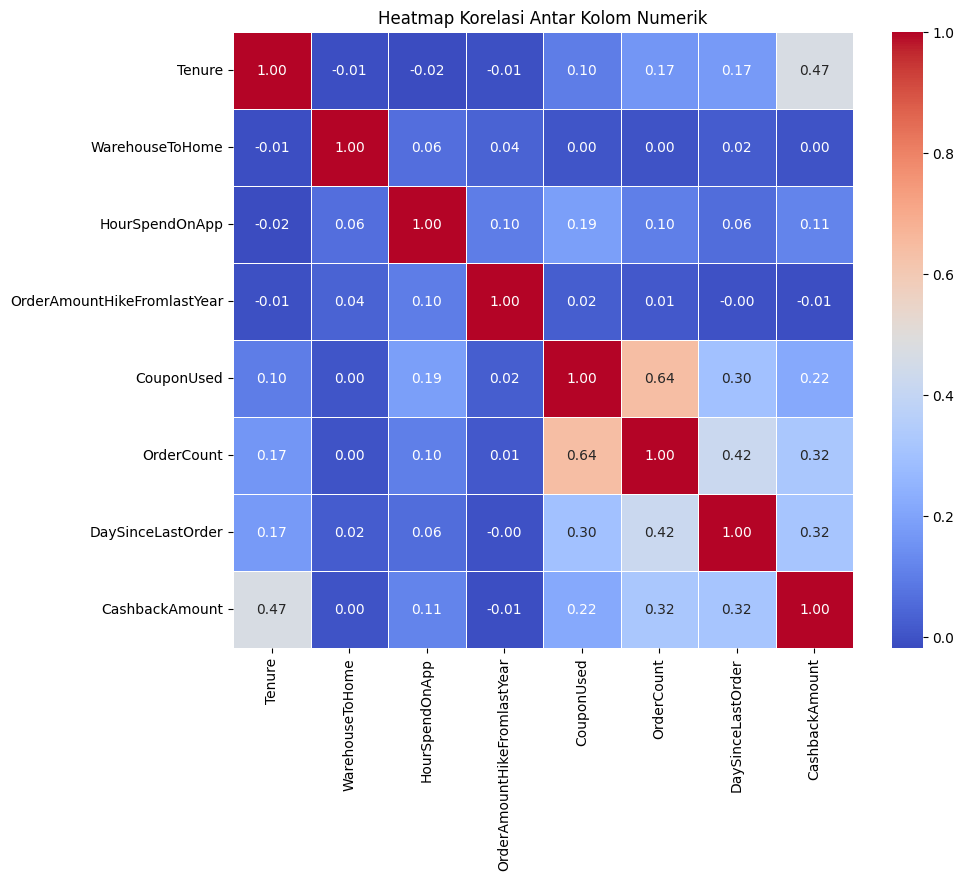

In [ ]:
# Heatmap korelasi (dengan angka) untuk kolom-kolom numerik terpilih
cols = [
    'Tenure', 'WarehouseToHome', 'HourSpendOnApp', 
    'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 
    'DaySinceLastOrder', 'CashbackAmount'
]

plt.figure(figsize=(10, 8))
sns.heatmap(df_clean[cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi Antar Kolom Numerik')
plt.show()

---
Representativitas data

1. Statistik deskriptif untuk melihat sebaran (mean, median, min, max)

In [ ]:

print(df[['Tenure', 'CashbackAmount', 'WarehouseToHome']].describe())

            Tenure  CashbackAmount  WarehouseToHome
count  5366.000000     5630.000000      5379.000000
mean     10.189899      177.221492        15.639896
std       8.557241       49.193869         8.531475
min       0.000000        0.000000         5.000000
25%       2.000000      146.000000         9.000000
50%       9.000000      163.000000        14.000000
75%      16.000000      196.000000        20.000000
max      61.000000      325.000000       127.000000


2. Cek proporsi/representasi data kategori (misal: status atau preferensi pelanggan)

In [ ]:
print(df['PreferredLoginDevice'].value_counts(normalize=True)) # Menampilkan dalam bentuk persentase (%)

PreferredLoginDevice
Mobile Phone    0.491119
Computer        0.290231
Phone           0.218650
Name: proportion, dtype: float64


3. Visualisasi distribusi untuk melihat apakah representasi data seimbang

Text(0.5, 1.0, 'Distribusi CashbackAmount (Representasi Nilai Pelanggan)')

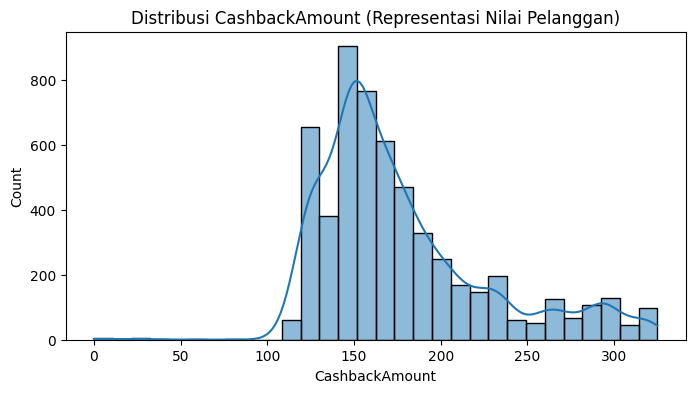

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(df['CashbackAmount'], kde=True, bins=30)
plt.title("Distribusi CashbackAmount (Representasi Nilai Pelanggan)")

---
## Bagian 4: Feature Engineering 

Tambahkan tiga kolom baru ke `df_clean`:
- `Total_Orders_Engagement` = jumlah `OrderCount` dan `CouponUsed`
- `Total_Devices_Addresses` = jumlah `NumberOfDeviceRegistered` dan `NumberOfAddress`
- `Avg_Hour_Per_Device` = `HourSpendOnApp` dibagi `NumberOfDeviceRegistered`
- `Total_Interactions` = penjumlahan dari `OrderCount`, `CouponUsed`, dan `Complain`

Tampilkan 5 baris pertama ketiga kolom tersebut.

In [ ]:
# Buat kolom fitur baru pada df_clean
# - Total_Orders_Engagement = OrderCount + CouponUsed
# - Total_Devices_Addresses = NumberOfDeviceRegistered + NumberOfAddress
# - Avg_Hour_Per_Device = HourSpendOnApp / NumberOfDeviceRegistered
# `Total_Interactions` = `OrderCount` + `CouponUsed` + `Complain`

df_clean['Total_Orders_Engagement'] = df_clean['OrderCount'] + df_clean['CouponUsed']
df_clean['Total_Devices_Addresses'] = df_clean['NumberOfDeviceRegistered'] + df_clean['NumberOfAddress']
df_clean['Avg_Hour_Per_Device'] = df_clean['HourSpendOnApp'] / df_clean['NumberOfDeviceRegistered'].replace(0, np.nan)
df_clean['Total_Interactions'] = df_clean['OrderCount'] + df_clean['CouponUsed'] + df_clean['Complain']

# tampilkan 5 baris pertama dari ketiga kolom baru tersebut
new_features = ['Total_Orders_Engagement', 'Total_Devices_Addresses', 'Avg_Hour_Per_Device', 'Total_Interactions']
display(df_clean[new_features].head())

,Total_Orders_Engagement,Total_Devices_Addresses,Avg_Hour_Per_Device,Total_Interactions
0,2.0,12,1.00,3.0
1,1.0,11,0.75,2.0
2,1.0,10,0.50,2.0
3,1.0,12,0.50,1.0
4,2.0,6,1.00,2.0


- Total_Orders_Engagement: Menggabungkan jumlah transaksi pesanan dan kupon yang digunakan untuk melihat tingkat keaktifan berbelanja pelanggan.

- Total_Devices_Addresses: Mengakumulasikan jumlah perangkat terdaftar serta alamat pengiriman untuk mencerminkan profil kemudahan akses atau mobilitas akun pelanggan.

- Avg_Hour_Per_Device: Menghitung rasio waktu penggunaan aplikasi terhadap jumlah perangkat yang terdaftar.

- Total_Interactions: Menggabungkan tingkat keaktifan belanja sekaligus riwayat komplain untuk melihat tingkat engagement total pelanggan.

-----
Melakukan *encoding* pada sisa kolom kategorikal nominal yang bertipe *object* (seperti jenis kelamin, metode pembayaran, kategori pesanan, dll.). 

Karena kolom-kolom ini tidak memiliki hierarki atau tingkatan matematis, kita menggunakan **One-Hot Encoding** (`pd.get_dummies`) agar algoritma *machine learning* atau *clustering* dapat memprosesnya dengan akurat tanpa menimbulkan bias relasi antar-kategori. Parameter `drop_first=True` juga diterapkan untuk menghindari masalah *multikolinearitas* (perangkap variabel dummy).

In [ ]:
# Cek kolom bertipe object/kategori
cat_columns = df_clean.select_dtypes(include=['object', 'string']).columns
print("Kolom Kategorikal:", list(cat_columns))

# Contoh menggunakan One-Hot Encoding atau Label Encoding sesuai kebutuhan model
# Menggunakan One-Hot Encoding untuk variabel kategorikal nominal:
df_encoded = pd.get_dummies(df_clean, columns=cat_columns, drop_first=True)

print("Ukuran dataset setelah encoding:", df_encoded.shape)

Kolom Kategorikal: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']
Ukuran dataset setelah encoding: (5630, 33)


----
Lakukan **encoding** pada `CityTier` menggunakan salah satu metode yang telah dipelajari dengan urutan tier 1 < tier 2 < tier 3 (nilai 0 sampai 2), simpan di kolom baru `CityTier_Encoded`. Tampilkan jumlah data tiap nilai. Jelaskan mengapa metode tersebut dipilih untuk kolom ini.

In [ ]:
# Lakukan encoding pada CityTier dengan pemetaan manual (Ordinal Encoding)
# Asumsi urutan: Tier 1 (0), Tier 2 (1), Tier 3 (2)
tier_mapping = {1: 0, 2: 1, 3: 2}
df_clean['CityTier_Encoded'] = df_clean['CityTier'].map(tier_mapping)

# Tampilkan jumlah data tiap nilai hasil encoding
print(df_clean['CityTier_Encoded'].value_counts())

CityTier_Encoded
0    3666
2    1722
1     242
Name: count, dtype: int64


Metode Ordinal Encoding (pemetaan manual) dipilih karena kolom CityTier memiliki sifat data ordinal, di mana kategori-kategorinya memiliki tingkatan atau hierarki yang jelas (Tier 1, Tier 2, Tier 3). Dengan memberikan nilai numerik berurutan (0, 1, 2), informasi urutan tingkat tier tersebut tetap dapat terbaca dan dimanfaatkan dengan baik oleh model machine learning tanpa menghilangkan makna hierarkinya.

### Train-Test Splitting ###

Membagi dataset menjadi data latih dan data uji dengan proporsi 80:20. Pembagian dilakukan untuk memisahkan data yang digunakan dalam proses clustering dan data untuk pengujian.

In [ ]:
# Memilih kolom numerik yang digunakan untuk pemodelan segmentasi
features_to_scale = [
    'Tenure',
    'WarehouseToHome',
    'HourSpendOnApp',
    'OrderCount',
    'CashbackAmount',
    'Total_Orders_Engagement'
]

X = df_clean[features_to_scale]

from sklearn.model_selection import train_test_split

# Membagi data dengan proporsi 80:20
X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

print("Jumlah data latih:", X_train.shape)
print("Jumlah data uji:", X_test.shape)

Jumlah data latih: (4504, 6)
Jumlah data uji: (1126, 6)


---
Lakukan **scaling** pada kolom-kolom numerik utama (misalnya `Tenure`, `WarehouseToHome`, `OrderCount`, `CashbackAmount`, dan fitur baru yang dibuat) dengan `StandardScaler` atau `MinMaxScaler` dan simpan hasilnya di `X_scaled`. Tampilkan 5 baris pertamanya. Jelaskan mengapa scaling diperlukan dan alasan memilih scaler tersebut.

In [ ]:

# Melakukan scaling menggunakan StandardScaler
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Menampilkan hasil scaling
print("Data Latih Setelah Scaling:")
display(X_train_scaled.head())

print("Data Uji Setelah Scaling:")
display(X_test_scaled.head())


Data Latih Setelah Scaling:


,Tenure,WarehouseToHome,HourSpendOnApp,OrderCount,CashbackAmount,Total_Orders_Engagement
4478,-1.087206,-0.428110,0.088855,-0.339656,-0.552810,-0.396461
3685,0.814685,-0.309538,1.508010,-0.339656,-0.226969,-0.165218
731,-1.206074,-0.783823,0.088855,-0.686317,-0.960112,-0.858947
291,-0.136260,-0.902395,-1.330301,-0.686317,-1.224859,-0.627704
184,-0.730601,-0.546681,-1.330301,-0.686317,-0.593540,-0.858947


Data Uji Setelah Scaling:


,Tenure,WarehouseToHome,HourSpendOnApp,OrderCount,CashbackAmount,Total_Orders_Engagement
4331,-1.087206,-1.020966,1.508010,-0.339656,-0.593540,-0.165218
1988,0.576949,-0.783823,0.088855,-0.686317,-0.512080,-0.627704
3443,0.339212,1.587602,0.088855,-0.339656,1.157858,-0.165218
4559,-0.611733,-1.020966,1.508010,0.353664,-0.613906,0.759755
4898,0.339212,-1.020966,1.508010,-0.339656,1.524430,1.684727


### 1. Mengapa Scaling Diperlukan?

Scaling diperlukan karena fitur numerik pada dataset e-commerce memiliki rentang nilai yang berbeda-beda. Misalnya, `OrderCount` memiliki nilai yang relatif kecil, sedangkan `CashbackAmount` memiliki nilai yang lebih besar. Perbedaan rentang ini dapat memengaruhi hasil clustering, terutama pada algoritma K-Means dan Hierarchical Clustering yang menggunakan perhitungan jarak.

Oleh karena itu, scaling dilakukan agar setiap fitur memiliki skala yang sebanding sehingga tidak ada fitur dengan nilai besar yang mendominasi perhitungan jarak. Pada penelitian ini, scaling diterapkan pada enam fitur yang telah dipilih untuk proses segmentasi pelanggan.

### 2. Alasan Memilih StandardScaler

StandardScaler dipilih karena mengubah data berdasarkan nilai rata-rata (mean) menjadi 0 dan standar deviasi menjadi 1. Dengan demikian, setiap fitur memiliki skala yang lebih seragam tanpa menghilangkan perbedaan pola atau variasi data.

Proses scaling dilakukan setelah pembagian dataset menjadi data latih sebesar 80% dan data uji sebesar 20%. StandardScaler terlebih dahulu mempelajari karakteristik data latih menggunakan `fit_transform()`, kemudian menerapkan transformasi yang sama pada data uji menggunakan `transform()`. Langkah ini dilakukan agar informasi dari data uji tidak memengaruhi proses pembentukan skala data latih.

### Penanganan Data Imbalance ###

Pada penelitian ini, penanganan data imbalance tidak dilakukan karena metode yang digunakan adalah clustering dengan algoritma K-Means. Berbeda dengan klasifikasi, clustering tidak menggunakan label kelas sebagai target yang perlu diseimbangkan. Oleh karena itu, teknik seperti oversampling, undersampling, dan SMOTE tidak diterapkan. Distribusi jumlah anggota pada setiap cluster akan dianalisis setelah proses clustering untuk mengetahui pola pengelompokan pelanggan.

### Penyimpanan Kode di CSV ###

In [ ]:

# Menyimpan data hasil preprocessing dan scaling
X_train_scaled.to_csv('X_train_scaled.csv', index=False)
X_test_scaled.to_csv('X_test_scaled.csv', index=False)

print("Data hasil preprocessing berhasil disimpan!")

Data hasil preprocessing berhasil disimpan!


---
## Bagian 5: K-Means Clustering

Buat **elbow plot**: jalankan K-Means untuk k = 2 sampai 10 pada `X_train_scaled` dan gambar grafik inertia terhadap k (lengkap dengan label sumbu). Gunakan `random_state=42` dan `n_init=10`. Berdasarkan plot tersebut, berapakah jumlah cluster (k) yang optimal?

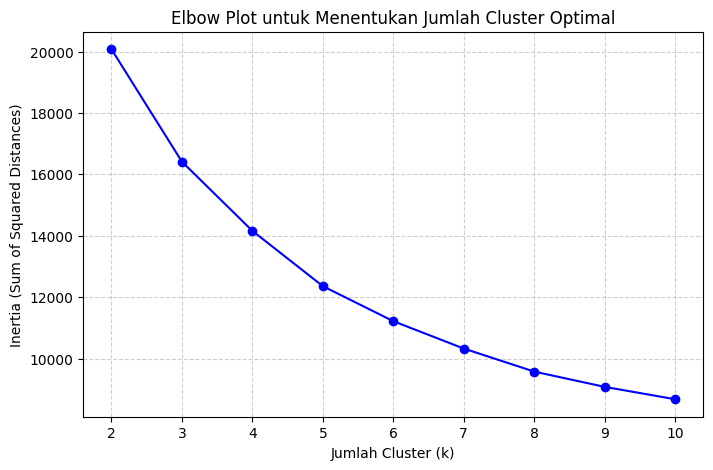

In [ ]:
# Jalankan K-Means untuk k = 2 sampai 10 dan simpan nilai inertia
inertia = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_train_scaled)
    inertia.append(kmeans.inertia_)

# Buat elbow plot (grafik inertia terhadap k)
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='-', color='b')
plt.title('Elbow Plot untuk Menentukan Jumlah Cluster Optimal')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia (Sum of Squared Distances)')
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Berdasarkan hasil Elbow Plot, pemilihan jumlah cluster dilakukan dengan mengamati perubahan nilai inertia pada setiap jumlah cluster (k). Semakin besar jumlah cluster, nilai inertia akan semakin kecil. Namun, penambahan cluster perlu dipertimbangkan ketika penurunannya mulai melandai.

Pada penelitian ini, jumlah cluster yang digunakan untuk proses segmentasi pelanggan adalah **k = 3**. Pemilihan tersebut didasarkan pada pertimbangan bentuk Elbow Plot serta kebutuhan untuk membagi pelanggan ke dalam tiga kelompok agar karakteristik setiap segmen lebih mudah dianalisis. Selanjutnya, hasil ini juga dibandingkan dengan evaluasi Silhouette Score untuk mengetahui kualitas pengelompokan.

---
Hitung **silhouette score** untuk k = 2 sampai 10 pada `X_train_scaled`.

In [ ]:
# Hitung silhouette score untuk k = 2..10
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_train_scaled)
    score = silhouette_score(X_train_scaled, labels)
    print(f"Jumlah Cluster (k) = {k}    | Silhouette Score = {score:.4f}")

Jumlah Cluster (k) = 2    | Silhouette Score = 0.3752
Jumlah Cluster (k) = 3    | Silhouette Score = 0.2821
Jumlah Cluster (k) = 4    | Silhouette Score = 0.2526
Jumlah Cluster (k) = 5    | Silhouette Score = 0.2460
Jumlah Cluster (k) = 6    | Silhouette Score = 0.2495
Jumlah Cluster (k) = 7    | Silhouette Score = 0.2445
Jumlah Cluster (k) = 8    | Silhouette Score = 0.2430
Jumlah Cluster (k) = 9    | Silhouette Score = 0.2492
Jumlah Cluster (k) = 10    | Silhouette Score = 0.2472


---
Pilih jumlah cluster `k` dan jelaskan alasannya berdasarkan *elbow plot* dan *silhouette score*. Jalankan K-Means final dengan `k` tersebut, tambahkan kolom `Cluster_KMeans` ke `df_clean`, dan tampilkan jumlah anggota tiap cluster.

In [ ]:

# Tentukan nilai k optimal berdasarkan observasi Elbow dan Silhouette
k_optimal = 3

# Jalankan algoritma K-Means final menggunakan data latih
kmeans_final = KMeans(
    n_clusters=k_optimal,
    random_state=42,
    n_init=10
)
kmeans_final.fit(X_train_scaled)

# Berikan label cluster pada data latih dan data uji
df_clean['Cluster_KMeans'] = 0
df_clean.loc[X_train.index, 'Cluster_KMeans'] = kmeans_final.labels_
df_clean.loc[X_test.index, 'Cluster_KMeans'] = kmeans_final.predict(X_test_scaled)

# Tampilkan jumlah anggota tiap cluster
print("Jumlah anggota tiap cluster:")
print(df_clean['Cluster_KMeans'].value_counts().sort_index())


Jumlah anggota tiap cluster:
Cluster_KMeans
0    3599
1     792
2    1239
Name: count, dtype: int64


Pemilihan k = 3 didasarkan pada pertimbangan hasil Elbow Plot, Silhouette Score, serta kebutuhan segmentasi pelanggan. Berdasarkan hasil Silhouette Score, nilai tertinggi diperoleh pada k = 2 sebesar 0,3752, sedangkan pada k = 3 diperoleh skor sebesar 0,2821. Meskipun k = 2 memiliki nilai Silhouette Score lebih tinggi, k = 3 dipilih agar pelanggan dapat dikelompokkan ke dalam tiga segmen yang lebih spesifik dan memudahkan analisis karakteristik pelanggan.

Berdasarkan hasil proses clustering K-Means dengan k = 3, diperoleh jumlah anggota sebagai berikut:
- Cluster 0: 3.599 pelanggan
- Cluster 1: 792 pelanggan
- Cluster 2: 1.239 pelanggan

Beberapa pertimbangan pemilihan k = 3 adalah sebagai berikut:

- **Berdasarkan Elbow Plot**, pemilihan tiga cluster mempertimbangkan titik ketika penurunan nilai inertia mulai melandai. Hal ini menunjukkan bahwa penambahan jumlah cluster berikutnya memberikan pengurangan inertia yang semakin kecil.
- **Berdasarkan kebutuhan segmentasi**, tiga kelompok pelanggan diharapkan dapat memberikan gambaran karakteristik yang lebih spesifik sehingga dapat digunakan sebagai dasar penyusunan strategi pemasaran yang berbeda untuk setiap segmen.

Dengan demikian, K-Means menggunakan tiga cluster sebagai model akhir untuk proses segmentasi pelanggan e-commerce.

---
Visualisasi Hasil K-Means

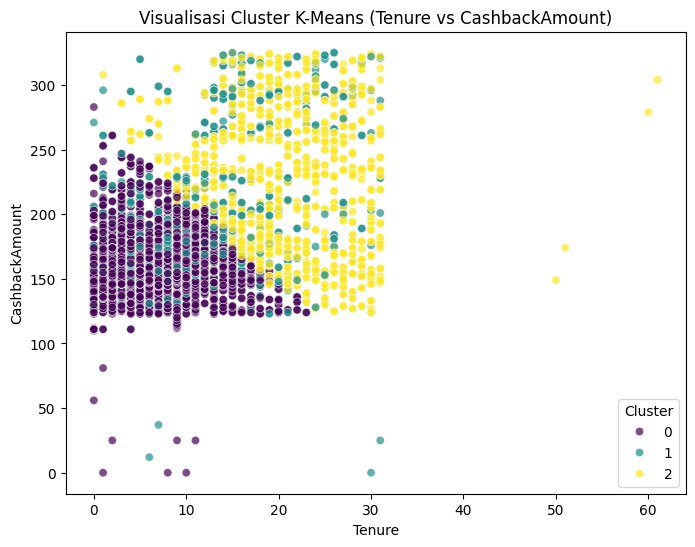

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=df_clean['Tenure'], 
    y=df_clean['CashbackAmount'], 
    hue=df_clean['Cluster_KMeans'], 
    palette='viridis', 
    data=df_clean, 
    alpha=0.7
)
plt.title('Visualisasi Cluster K-Means (Tenure vs CashbackAmount)')
plt.xlabel('Tenure')
plt.ylabel('CashbackAmount')
plt.legend(title='Cluster')
plt.show()

---
Profil dan Interpretasi Cluster K-Means

In [ ]:
cluster_profile_kmeans = df_clean.groupby('Cluster_KMeans')[features_to_scale].mean()
display(cluster_profile_kmeans)

,Tenure,WarehouseToHome,HourSpendOnApp,OrderCount,CashbackAmount,Total_Orders_Engagement
Cluster_KMeans,,,,,,
0,6.085857,15.399555,2.906641,1.843568,155.130870,2.993609
1,11.901515,15.250000,2.994949,9.070707,200.500000,13.614899
2,20.763519,16.255044,2.977401,2.305085,226.509282,3.861178


---
## Bagian 6: Hierarchical Clustering

Buat linkage `ward` dari `X_train_scaled` dan gambar **dendrogram** (petunjuk: gunakan `truncate_mode='lastp'` dan `p=20` agar mudah dibaca). Tentukan jumlah cluster dari dendrogram tersebut dan jelaskan alasannya.

In [ ]:
linkage_list=['single','complete','average','ward']
k_list = [2,3,4,5]

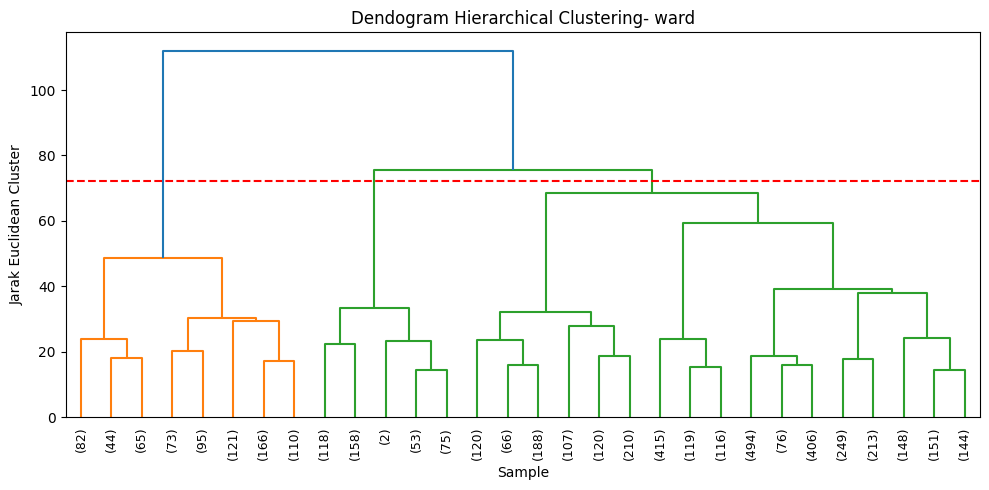

In [ ]:
def get_cut_height(Z, k) : 
    n = Z.shape[0] + 1
    height_before = Z[n - k - 1, 2]
    height_after = Z[n - k, 2]
    return (height_before + height_after) / 2


def plot_dendrogram(link, k_cut=None) :
    plt.figure(figsize=(10,5))
    dendrogram(
        Z, truncate_mode = 'lastp', p = 30,
        leaf_rotation = 90, 
        leaf_font_size = 9
    )

    if k_cut is not None : 
        plt.axhline(y=get_cut_height(Z, k_cut), color='red', linestyle='--')

    plt.title(f"Dendogram Hierarchical Clustering- {link}")
    plt.xlabel('Sample')
    plt.ylabel('Jarak Euclidean Cluster')
    plt.tight_layout()
    plt.show()

link = 'ward'
Z = linkage(X_train_scaled, method=link, metric='euclidean')

plot_dendrogram(link, 3)

---
Jalankan `AgglomerativeClustering`. Simpan hasilnya di kolom `Cluster_Hier`.

In [ ]:
# Menjalankan Agglomerative Clustering dengan jumlah cluster k = 3
model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
# Melakukan clustering pada data latih
train_labels = model.fit_predict(X_train_scaled)

# Menyimpan label cluster ke dataframe
df_clean['Cluster_Hier'] = -1
df_clean.loc[X_train.index, 'Cluster_Hier'] = train_labels
# Menampilkan distribusi anggota klaster Hierarchical
print("Jumlah anggota tiap cluster (Hierarchical):")
print(df_clean['Cluster_Hier'].value_counts().sort_index())

Jumlah anggota tiap cluster (Hierarchical):
Cluster_Hier
-1    1126
 0    3342
 1     756
 2     406
Name: count, dtype: int64


---
Perbandingan Sillhouette Score

In [ ]:
# Evaluasi Silhouette Score untuk berbagai linkage pada k = 3
hier_sil_scores = {}
for link in linkage_list:
    model_hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage=link)
    labels = model_hc.fit_predict(X_train_scaled)
    hier_sil_scores[link] = silhouette_score(X_train_scaled, labels)

# Menampilkan perbandingan Silhouette Score antar Linkage
df_sil_hier = pd.DataFrame(list(hier_sil_scores.items()), columns=['Linkage', 'Silhouette Score'])
print("Perbandingan Silhouette Score Hierarchical Clustering:")
display(df_sil_hier)

Perbandingan Silhouette Score Hierarchical Clustering:


,Linkage,Silhouette Score
0,single,0.588825
1,complete,0.497410
2,average,0.489688
3,ward,0.301822


---
Heatmap Cluster Hierarchial

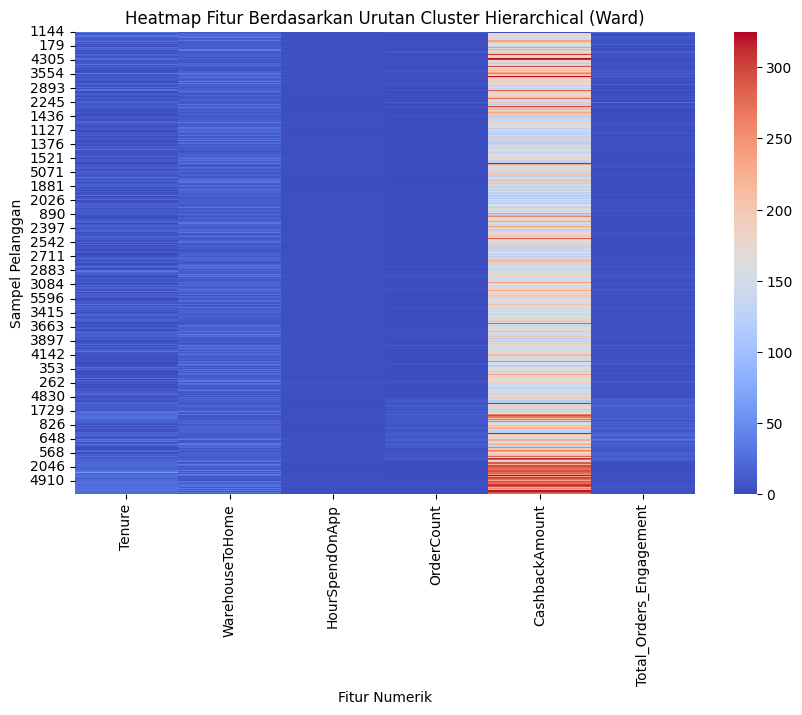

In [ ]:
plt.figure(figsize=(10, 6))
df_sorted = df_clean.sort_values('Cluster_Hier')
sns.heatmap(df_sorted[features_to_scale], cmap='coolwarm', cbar=True)
plt.title('Heatmap Fitur Berdasarkan Urutan Cluster Hierarchical (Ward)')
plt.xlabel('Fitur Numerik')
plt.ylabel('Sampel Pelanggan')
plt.show()

---
Profil dan Interpretasi Cluster Hierarchical

In [ ]:
cluster_profile_hier = df_clean.groupby('Cluster_Hier')[features_to_scale].mean()
print("Profil Rata-rata Fitur per Cluster (Hierarchical):")
display(cluster_profile_hier)

Profil Rata-rata Fitur per Cluster (Hierarchical):


,Tenure,WarehouseToHome,HourSpendOnApp,OrderCount,CashbackAmount,Total_Orders_Engagement
Cluster_Hier,,,,,,
-1,10.085258,15.391652,2.923623,2.889876,177.527531,4.535524
0,8.145422,15.844105,2.954518,1.908438,159.487732,3.126571
1,12.542328,13.719577,2.933862,8.202381,205.579365,12.407407
2,22.155172,17.209360,2.802956,2.073892,269.544335,3.460591


---
## Bagian 7: Interpretasi Hasil

(a) Tampilkan `pd.crosstab` antara `Cluster_KMeans` dan `MaritalStatus`.

(b) Apakah *silhouette score* yang kamu peroleh berarti clusternya bagus? Bandingkan secara singkat dengan hasil Hierarchical Clustering.

Crosstab Cluster K-Means vs Marital Status:


MaritalStatus,Divorced,Married,Single
Cluster_KMeans,,,
0,495,1824,1280
1,134,459,199
2,219,703,317


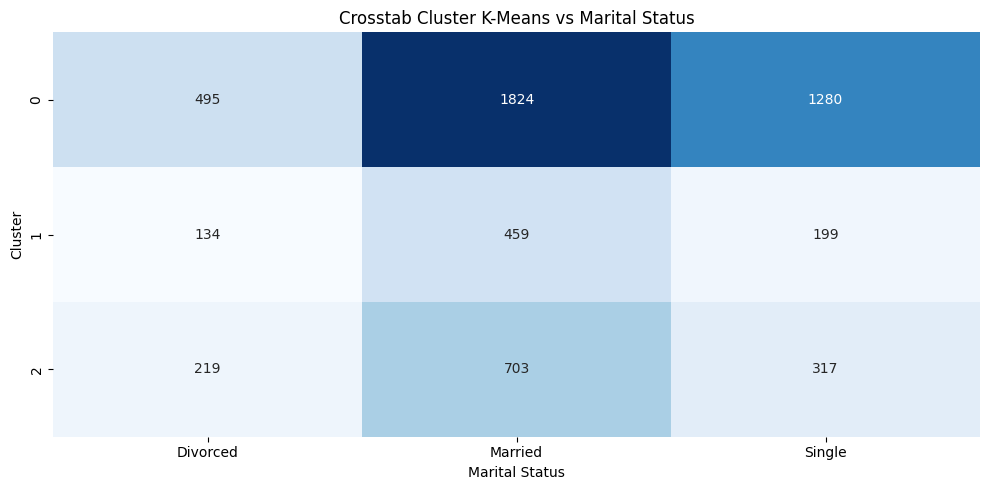

In [ ]:
# (a) Menampilkan crosstab antara Cluster K-Means dan status pernikahan (MaritalStatus)
crosstab_result = pd.crosstab(df_clean['Cluster_KMeans'], df_clean['MaritalStatus'])

print("Crosstab Cluster K-Means vs Marital Status:")
display(crosstab_result)

k_compare = 3

plt.figure(figsize=(10,5))
ct = pd.crosstab(df_clean['Cluster_KMeans'], df_clean['MaritalStatus'], rownames=['Cluster'], colnames=['Marital Status'])

sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar=False)

plt.title('Crosstab Cluster K-Means vs Marital Status')
plt.tight_layout()
plt.show()

In [ ]:

# Evaluasi Silhouette Score Hierarchical Clustering
silhouette_hier = silhouette_score(X_train_scaled, train_labels)

print("Silhouette Score Hierarchical Clustering:", silhouette_hier)

# Semakin mendekati 1, semakin baik hasil clustering


Silhouette Score Hierarchical Clustering: 0.30182184437264525


**Evaluasi Silhouette Score:** Skor Silhouette K-Means sebesar **0.2821 untuk k=3** menunjukkan bahwa hasil pengelompokan pelanggan masih memiliki tingkat pemisahan yang terbatas. Nilai yang berada di bawah 0.5 mengindikasikan bahwa batas antarcluster belum terlalu tegas dan masih terdapat kemungkinan tumpang tindih karakteristik pelanggan. Kondisi ini cukup wajar pada data E-Commerce karena perilaku dan preferensi pelanggan, seperti jumlah transaksi, durasi penggunaan aplikasi, dan besaran cashback, dapat memiliki pola yang saling berdekatan. Berdasarkan pengujian Silhouette Score, nilai tertinggi K-Means diperoleh pada **k=2 sebesar 0.3752**, sedangkan jumlah cluster yang digunakan pada pemodelan akhir adalah 3 berdasarkan pertimbangan hasil Elbow Method dan kebutuhan segmentasi.

**Perbandingan dengan Hierarchical Clustering:** Berdasarkan hasil evaluasi pada data latih, K-Means dengan 3 cluster memperoleh Silhouette Score sebesar **0.2821**, sedangkan Hierarchical Clustering dengan metode Ward memperoleh skor sebesar **0.3018**. Hasil tersebut menunjukkan bahwa metode Ward memiliki kualitas pemisahan cluster sedikit lebih baik dibandingkan K-Means pada pengujian ini. Sementara itu, pengujian berbagai metode linkage pada Hierarchical Clustering menunjukkan bahwa Single Linkage memperoleh Silhouette Score tertinggi sebesar **0.5888**. Dengan demikian, setiap metode menghasilkan kualitas pengelompokan yang berbeda. K-Means membentuk cluster berdasarkan kedekatan data terhadap centroid, sedangkan Hierarchical Clustering membentuk kelompok melalui proses penggabungan data secara bertahap.

---
Perbandingan Hasil K-Means dan Hierarchical

In [38]:

comparison_summary = pd.DataFrame({
    'Metode': ['K-Means', 'Hierarchical Clustering (Ward)'],
    'Jumlah Cluster': [3, 3],
    'Silhouette Score': [
        silhouette_score(X_train_scaled, kmeans_final.labels_),
        silhouette_score(X_train_scaled, train_labels)
    ]
})

print("Tabel Perbandingan K-Means vs Hierarchical:")
display(comparison_summary)


Tabel Perbandingan K-Means vs Hierarchical:


,Metode,Jumlah Cluster,Silhouette Score
0,K-Means,3,0.282070
1,Hierarchical Clustering (Ward),3,0.301822


---
## Bagian 8 : Simpan Model & Scaler

In [39]:
import joblib

# 1. Simpan model K-Means final dan StandardScaler
joblib.dump(kmeans_final, 'model_kmeans.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model K-Means dan Scaler berhasil disimpan!")

Model K-Means dan Scaler berhasil disimpan!
